# Exploring Plant Image Segmentation

Compare plant tissue, background, and shadows in RGB and HSV color
spaces to identify useful features for estimating projected plant area.

The analysis begins with one photograph cropped to retain the plant
and its immediate surroundings.

### How to use this notebook

This notebook records an exploratory sequence, including methods that did not work well. Run setup cells before dependent analyses. Interactive cells open a separate Tk window: finish selections with Enter and turn toolbar zoom off before sampling. Rerunning selection cells replaces the corresponding in-memory selections. Saved CSV and NPZ files preserve the labeled points and region images; restarting the kernel clears Python variables. Existing figures are saved outputs from earlier runs, not proof that their variables are currently loaded.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.path import Path as PolygonPath
from matplotlib.colors import rgb_to_hsv

### Load project inputs

The paths below point to the local Windows project. The morphology table links plants and branches to photographs; the GoPro metadata table is loaded for later use but is not used to calibrate area in the analyses below. Image intensities here are digital numbers, not calibrated optical measurements.

In [ ]:
# Project paths.
project_folder = Path(r"C:\Users\mguar\Documents\OEAS805\FinalProject")
raw_folder = project_folder / "DATA" / "raw"
image_folder = raw_folder / "GoProImages_Susquehanna_Milfoil"

# Load the data tables.
morphmeasures = pd.read_excel(
    raw_folder / "Morphmeasures_Susquehanna_milfoil.xlsx"
)
gopro_metadata = pd.read_excel(
    raw_folder / "GoPro_Metadata_Susquehanna_milfoil.xlsx"
)

### Inspect plant IDX 2

Multiple morphology rows can describe measurements from the same branch. Repeated image names do not imply different photographs. This inspection establishes which records belong to IDX 2.

In [ ]:
morphmeasures = pd.read_excel(
    raw_folder / "Morphmeasures_Susquehanna_milfoil.xlsx"
)

idx2 = morphmeasures.loc[morphmeasures["IDX"] == 2]

display(idx2)

,BRANCH,REFERENCE,IDX,PLANTCOND,SITE,SPECIES,BRANCHNUM,PART_TYPE,NODENUM,LEAFNUM,LEN_CM,WID_MM,WET_WT
0,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.3,0.29,2.4777
1,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.5,0.29,-999.0000
2,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.6,0.29,-999.0000
3,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.5,0.29,-999.0000
4,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.7,0.29,-999.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
338,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,2,1.7,0.29,-999.0000
339,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,2,1.7,0.29,-999.0000
340,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,2,0.6,0.29,-999.0000
341,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,2,1.5,0.29,-999.0000


### Match the reference and branch photographs

Select the first row for IDX 2, branch 1, because its repeated measurement rows share the same image links. REFERENCE identifies the reference photograph and BRANCH identifies the branch photograph. Matching stems allows names with or without extensions.

In [16]:
row = morphmeasures.loc[
    (morphmeasures["IDX"] == 2)
    & (morphmeasures["BRANCHNUM"] == 1)
].iloc[0]

# Match image names with or without file extensions.
image_lookup = {
    path.stem.upper(): path
    for path in image_folder.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
}

reference_path = image_lookup[
    Path(str(row["REFERENCE"]).strip()).stem.upper()
]
branch_path = image_lookup[
    Path(str(row["BRANCH"]).strip()).stem.upper()
]

with Image.open(reference_path) as img:
    reference_rgb = np.array(img.convert("RGB"))

with Image.open(branch_path) as img:
    branch_rgb = np.array(img.convert("RGB"))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(reference_rgb)
axes[0].set_title(f"IDX 2 — Reference\n{reference_path.name}")

axes[1].imshow(branch_rgb)
axes[1].set_title(f"IDX 2 — Branch 1\n{branch_path.name}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Define the whole-branch region of interest aka just the plant crop

Draw a polygon around the branch and nearby background. This is an analysis boundary, not a plant segmentation: background inside the polygon must still be classified. branch_crop is the bounding rectangle; roi_mask identifies pixels inside the polygon. Coordinates within this crop differ from coordinates in the original photograph.

In [17]:
%matplotlib tk

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(branch_rgb)
ax.set_title("Click around the branch; press Enter to finish")
ax.axis("off")

points = plt.ginput(n=-1, timeout=0)
plt.close(fig)

if len(points) < 3:
    raise ValueError("Select at least three points.")

# Create a mask for the selected region.
vertices = np.array(points)
polygon = PolygonPath(
    np.vstack([vertices, vertices[0]]),
    closed=True
)

height, width = branch_rgb.shape[:2]
yy, xx = np.mgrid[:height, :width]

roi_mask_full = polygon.contains_points(
    np.column_stack([xx.ravel(), yy.ravel()])
).reshape(height, width)

# Crop to the selected region's bounding rectangle.
rows, cols = np.where(roi_mask_full)

if rows.size == 0:
    raise ValueError("The polygon contains no pixels. Try a larger selection.")

y0, y1 = rows.min(), rows.max() + 1
x0, x1 = cols.min(), cols.max() + 1

branch_crop = branch_rgb[y0:y1, x0:x1].copy()
roi_mask = roi_mask_full[y0:y1, x0:x1]

# Only these pixels will enter our brightness analysis.
roi_pixels = branch_crop[roi_mask]

### Check the crop out

Pixels outside the polygon are transparent. The white surface inside it remains part of the analysis. Check that fine leaflet tips have not been excluded before continuing.

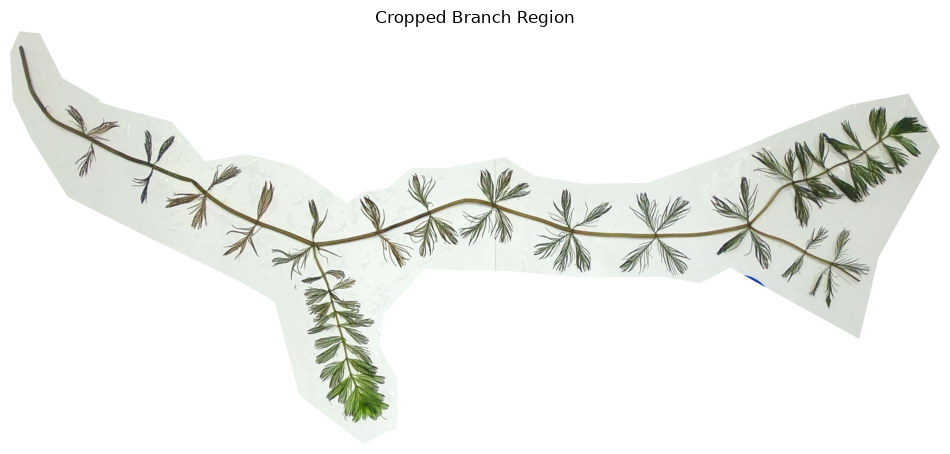

In [18]:
%matplotlib inline

# Make pixels outside the selected polygon transparent.
preview = np.dstack([
    branch_crop,
    roi_mask.astype(np.uint8) * 255
])

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(preview)
ax.set_title("Cropped Branch Region")
ax.axis("off")
plt.show()

### Explore the RGB intensity distributions

These histograms count all pixels inside the polygon, including plant and background. Peaks describe intensity groups, not verified classes. A large bright peak may reflect the white surface, but class identity must be checked against the photograph.

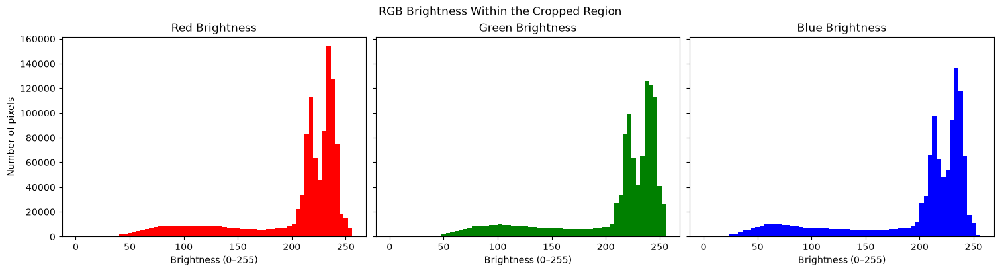

In [7]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4),
    sharex=True, sharey=True,
    constrained_layout=True
)

for channel, color in enumerate(["red", "green", "blue"]):
    axes[channel].hist(
        roi_pixels[:, channel],
        bins=64,
        range=(0, 256),
        color=color
    )
    axes[channel].set_title(f"{color.capitalize()} Brightness")
    axes[channel].set_xlabel("Brightness (0–255)")

axes[0].set_ylabel("Number of pixels")
fig.suptitle("RGB Brightness Within the Cropped Region")
plt.show()

### Locate RGB contrast in the photograph

Each map shows one channel on a common 0–255 scale. The rainbow ramp is a display choice: it adds no information and does not define the plant boundary. Spatial maps help locate bright tissue, dark tissue, shadows, and background variation.

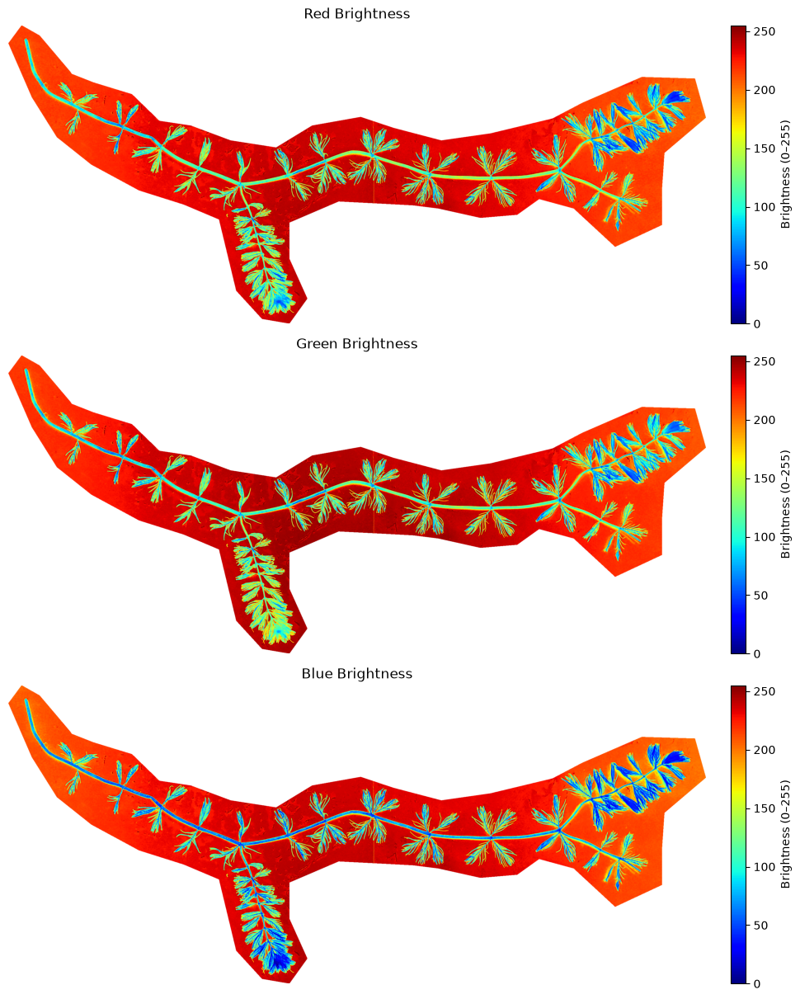

In [8]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 12),
    constrained_layout=True
)

for channel, name in enumerate(["Red", "Green", "Blue"]):
    # Hide pixels outside the cropping polygon.
    brightness = np.ma.array(
        branch_crop[:, :, channel],
        mask=~roi_mask
    )

    im = axes[channel].imshow(
        brightness,
        cmap="jet",
        vmin=0,
        vmax=255
    )

    axes[channel].set_title(f"{name} Brightness")
    axes[channel].axis("off")

    colorbar = fig.colorbar(
        im,
        ax=axes[channel],
        fraction=0.025,
        pad=0.02
    )
    colorbar.set_label("Brightness (0–255)")

plt.show()

### Explore HSV channels 

Convert floating-point RGB values normalized by 255 into Hue, Saturation, and Value. Hue describes color family, Saturation describes relative channel spread, and Value is the maximum normalized RGB channel. HSV rearranges information already present in RGB; it does not add a new measurement. Hue is circular and becomes unreliable as saturation approaches zero.

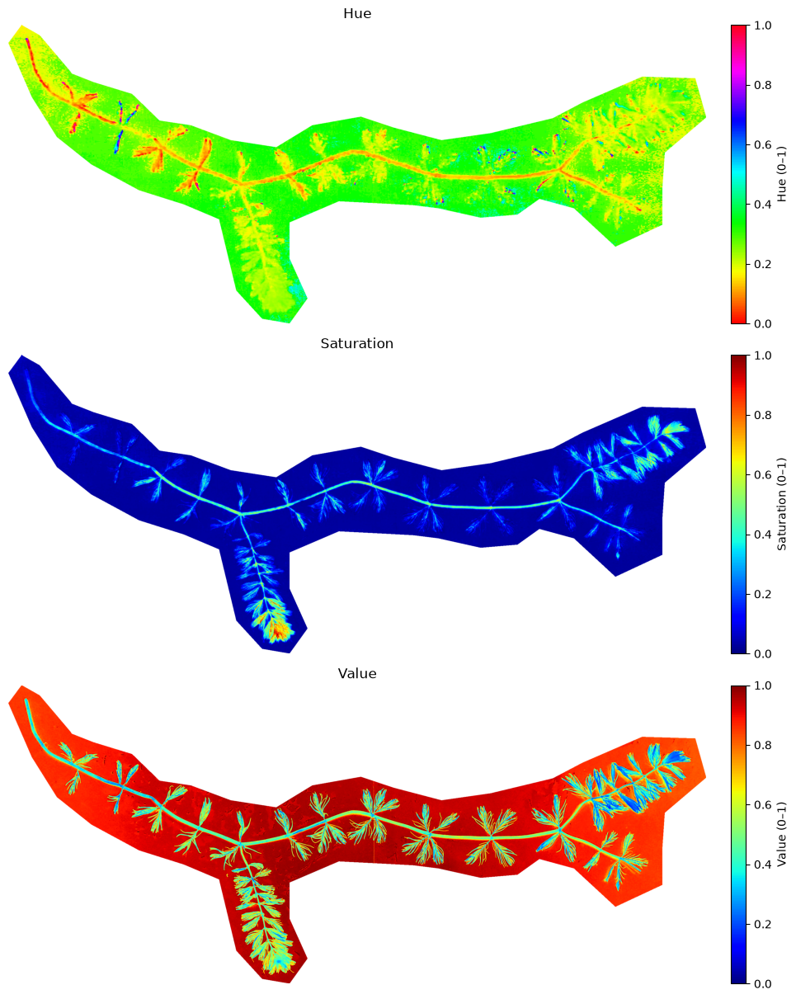

In [9]:
# Convert RGB (0–255) to HSV (0–1).
hsv_crop = rgb_to_hsv(branch_crop.astype(float) / 255.0)

# Selected pixels only, for later histograms.
hsv_pixels = hsv_crop[roi_mask]

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 12),
    constrained_layout=True
)

names = ["Hue", "Saturation", "Value"]
cmaps = ["hsv", "jet", "jet"]

for channel, (name, cmap) in enumerate(zip(names, cmaps)):
    values = np.ma.array(
        hsv_crop[:, :, channel],
        mask=~roi_mask
    )

    im = axes[channel].imshow(
        values,
        cmap=cmap,
        vmin=0,
        vmax=1
    )

    axes[channel].set_title(name)
    axes[channel].axis("off")

    colorbar = fig.colorbar(
        im,
        ax=axes[channel],
        fraction=0.025,
        pad=0.02
    )
    colorbar.set_label(f"{name} (0–1)")

plt.show()

### Compare the RGB intensity with HSV value

All four panels use the same 0–1 grayscale display. Value is max(r, g, b) at each pixel, rather than an average brightness. Dividing RGB by 255 changes units but neither creates contrast nor makes the distribution normal.

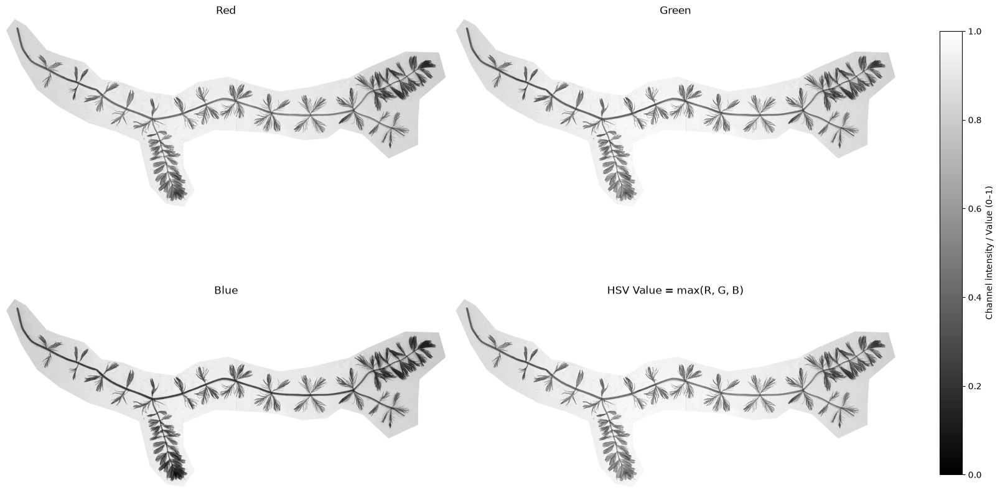

In [10]:
# Normalize RGB to match the HSV scale.
rgb_normalized = branch_crop.astype(float) / 255.0

panels = [
    ("Red", rgb_normalized[:, :, 0]),
    ("Green", rgb_normalized[:, :, 1]),
    ("Blue", rgb_normalized[:, :, 2]),
    ("HSV Value = max(R, G, B)", hsv_crop[:, :, 2])
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 9),
    constrained_layout=True
)

for ax, (title, values) in zip(axes.flat, panels):
    im = ax.imshow(
        np.ma.array(values, mask=~roi_mask),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(title)
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label="Channel intensity / Value (0–1)"
)

plt.show()

In [4]:
from scipy.ndimage import uniform_filter

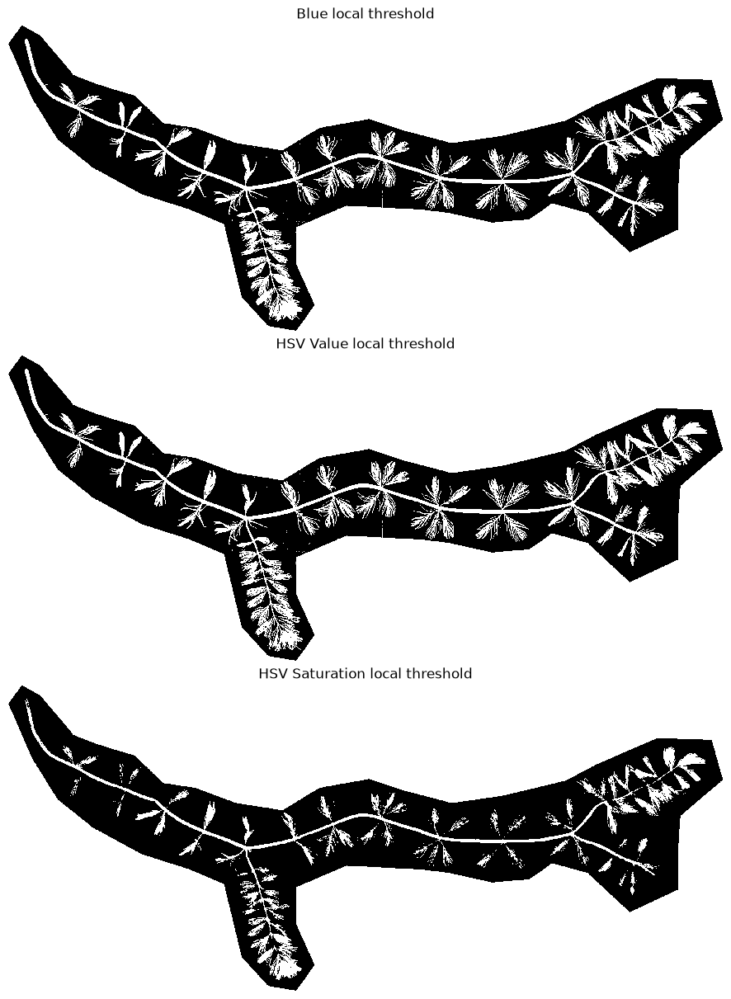

In [12]:
# Starting settings—not validated thresholds.
window_size = 101  # Neighborhood width and height, in pixels.
offset = 0.05     # Required difference from the local mean (0–1).

blue = branch_crop[:, :, 2].astype(float) / 255.0
value = hsv_crop[:, :, 2]
saturation = hsv_crop[:, :, 1]

# Fraction of each neighborhood inside the polygon.
weights = uniform_filter(
    roi_mask.astype(float),
    size=window_size,
    mode="constant",
    cval=0
)

def local_mean(channel):
    weighted_mean = uniform_filter(
        channel * roi_mask,
        size=window_size,
        mode="constant",
        cval=0
    )

    return np.divide(
        weighted_mean,
        weights,
        out=np.zeros_like(channel),
        where=weights > 0
    )

# Candidate plant masks.
blue_mask = roi_mask & (blue < local_mean(blue) - offset)
value_mask = roi_mask & (value < local_mean(value) - offset)
saturation_mask = roi_mask & (
    saturation > local_mean(saturation) + offset
)

# Compare the results.
fig, axes = plt.subplots(
    3, 1, figsize=(16, 12),
    constrained_layout=True
)

for ax, title, mask in zip(
    axes,
    ["Blue local threshold",
     "HSV Value local threshold",
     "HSV Saturation local threshold"],
    [blue_mask, value_mask, saturation_mask]
):
    ax.imshow(
        np.ma.array(mask, mask=~roi_mask),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.set_title(title)
    ax.axis("off")

plt.show()

In [13]:
%matplotlib tk

regions = {}

for name in ["Dense", "Sparse", "Bare"]:
    fig, ax = plt.subplots(figsize=(14, 8))

    preview = np.dstack([
        branch_crop,
        roi_mask.astype(np.uint8) * 255
    ])

    ax.imshow(preview)
    ax.set_title(f"{name}: click two opposite corners")
    ax.axis("off")

    points = plt.ginput(2, timeout=0)
    plt.close(fig)

    if len(points) != 2:
        raise ValueError("Select two corners for each region.")

    corners = np.array(points)

    x0, y0 = np.floor(corners.min(axis=0)).astype(int)
    x1, y1 = np.ceil(corners.max(axis=0)).astype(int)

    height, width = roi_mask.shape
    x0, x1 = np.clip([x0, x1], 0, width)
    y0, y1 = np.clip([y0, y1], 0, height)

    if x1 <= x0 or y1 <= y0:
        raise ValueError("Select a rectangle with a nonzero area.")

    regions[name] = {
        "rgb": branch_crop[y0:y1, x0:x1].copy(),
        "roi": roi_mask[y0:y1, x0:x1].copy(),
        "bounds": (x0, y0, x1, y1)
    }

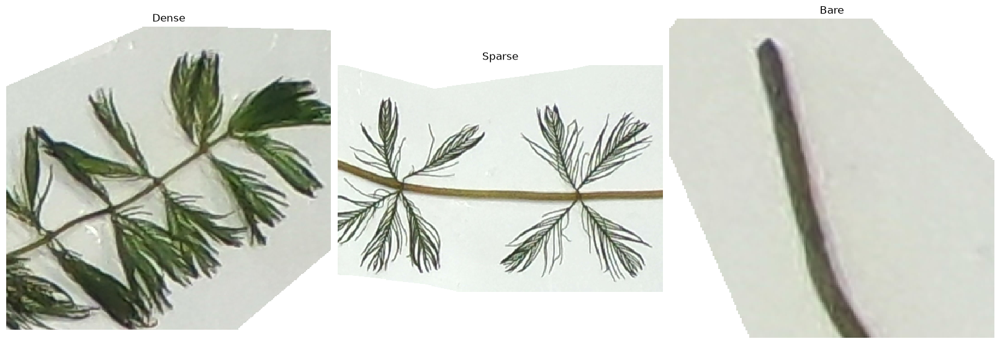

In [14]:
%matplotlib inline

fig, axes = plt.subplots(
    1, 3, figsize=(16, 6),
    constrained_layout=True
)

for ax, (name, region) in zip(axes, regions.items()):
    preview = np.dstack([
        region["rgb"],
        region["roi"].astype(np.uint8) * 255
    ])

    ax.imshow(preview, interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")

plt.show()

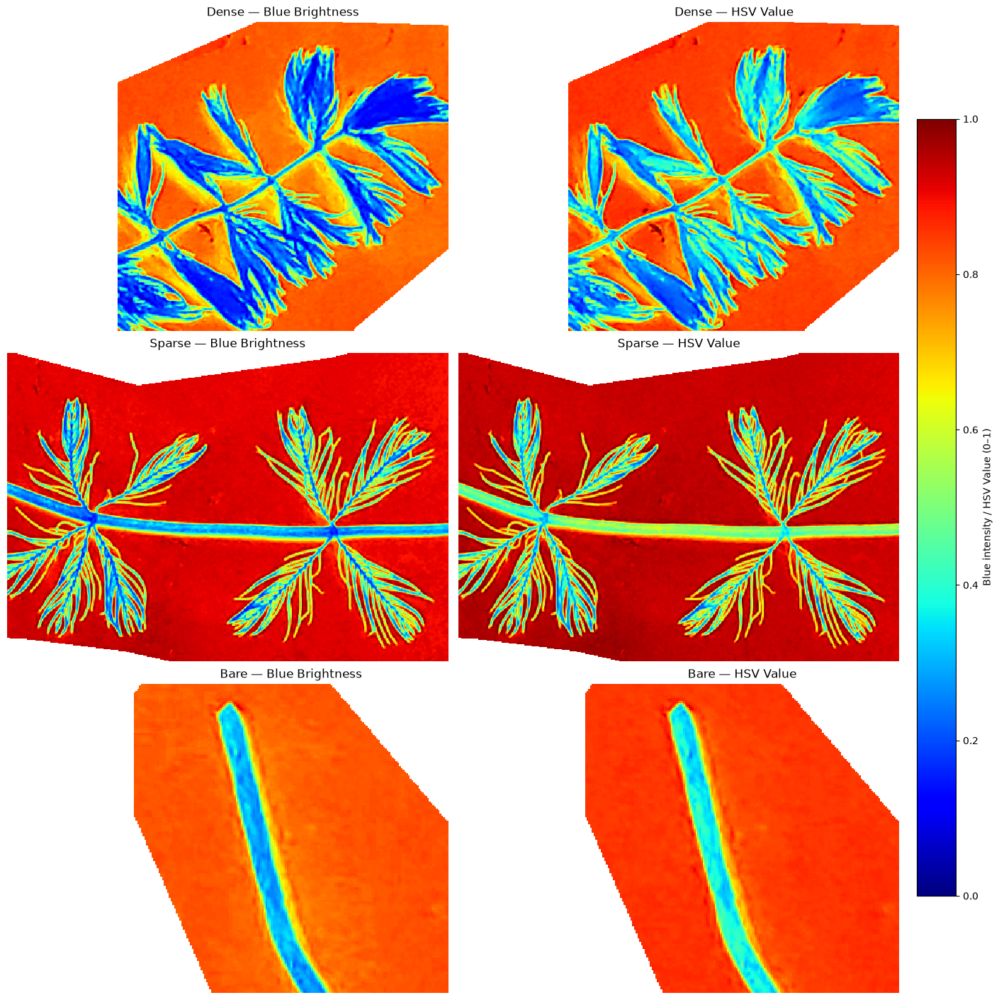

In [15]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 14),
    constrained_layout=True
)

for row, (name, region) in enumerate(regions.items()):
    rgb_region = region["rgb"].astype(float) / 255.0
    hsv_region = rgb_to_hsv(rgb_region)

    channels = [
        ("Blue Brightness", rgb_region[:, :, 2]),
        ("HSV Value", hsv_region[:, :, 2])
    ]

    for col, (label, values) in enumerate(channels):
        im = axes[row, col].imshow(
            np.ma.array(values, mask=~region["roi"]),
            cmap="jet",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        axes[row, col].set_title(f"{name} — {label}")
        axes[row, col].axis("off")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    pad=0.02,
    label="Blue intensity / HSV Value (0–1)"
)

plt.show()

In [19]:
%matplotlib tk

line_profiles = {}

for name in ["Dense", "Sparse", "Bare"]:
    region = regions[name]
    rgb_region = region["rgb"]
    valid_region = region["roi"]
    height, width = valid_region.shape

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(
        np.dstack([
            rgb_region,
            valid_region.astype(np.uint8) * 255
        ]),
        interpolation="nearest"
    )

    target = "stem" if name == "Bare" else "one leaflet"
    ax.set_title(
        f"{name}: click two endpoints across {target}\n"
        "Start and end on background"
    )

    points = plt.ginput(2, timeout=0)
    plt.close(fig)

    if len(points) != 2:
        raise ValueError(f"{name}: select two endpoints.")

    start, end = np.array(points)
    length = np.linalg.norm(end - start)

    if length < 1:
        raise ValueError(f"{name}: endpoints are too close.")

    sample_count = int(np.ceil(length)) + 1
    xs = np.linspace(start[0], end[0], sample_count)
    ys = np.linspace(start[1], end[1], sample_count)

    xi = np.rint(xs).astype(int)
    yi = np.rint(ys).astype(int)

    if (
        (xi < 0).any() or (xi >= width).any()
        or (yi < 0).any() or (yi >= height).any()
    ):
        raise ValueError(f"{name}: keep endpoints inside the image.")

    if not valid_region[yi, xi].all():
        raise ValueError(f"{name}: keep the line inside the crop polygon.")

    hsv_region = rgb_to_hsv(rgb_region.astype(float) / 255.0)

    line_profiles[name] = {
        "rgb": rgb_region,
        "xs": xs,
        "ys": ys,
        "distance": np.linspace(0, length, sample_count),
        "blue": rgb_region[yi, xi, 2].astype(float) / 255.0,
        "saturation": hsv_region[yi, xi, 1]
    }

print("Saved profiles:", ", ".join(line_profiles))

Saved profiles: Dense, Sparse, Bare


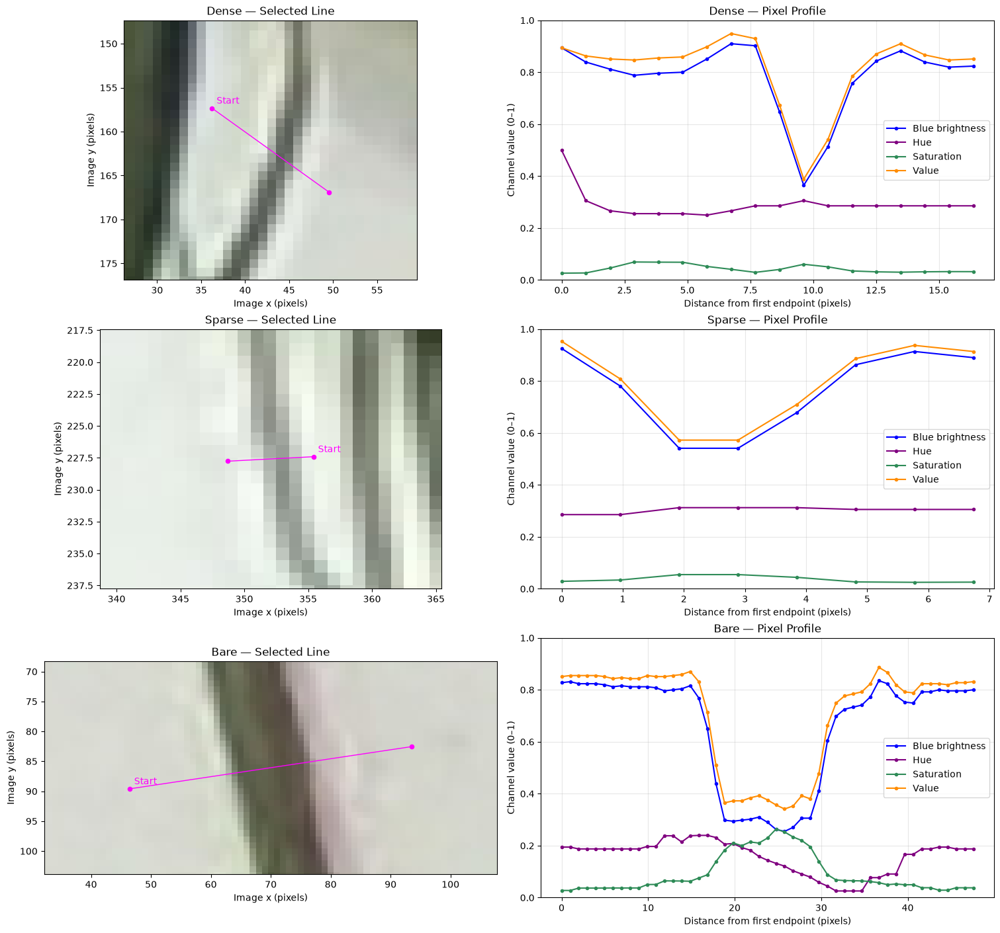

In [24]:
%matplotlib inline

fig, axes = plt.subplots(
    3, 2, figsize=(15, 14),
    constrained_layout=True
)

for row, (name, profile) in enumerate(line_profiles.items()):
    rgb_region = profile["rgb"]
    xs, ys = profile["xs"], profile["ys"]
    distance = profile["distance"]
    height, width = rgb_region.shape[:2]

    # Extract HSV channels along the saved line.
    hsv_region = rgb_to_hsv(rgb_region.astype(float) / 255.0)

    xi = np.rint(xs).astype(int)
    yi = np.rint(ys).astype(int)

    profile["hue"] = hsv_region[yi, xi, 0]
    profile["saturation"] = hsv_region[yi, xi, 1]
    profile["value"] = hsv_region[yi, xi, 2]

    # Original photograph with the sampled line.
    ax = axes[row, 0]
    ax.imshow(rgb_region, interpolation="nearest")
    ax.plot(xs, ys, color="magenta", linewidth=1)

    ax.scatter(
        [xs[0], xs[-1]],
        [ys[0], ys[-1]],
        color="magenta",
        s=20
    )

    ax.annotate(
        "Start",
        (xs[0], ys[0]),
        xytext=(5, 5),
        textcoords="offset points",
        color="magenta"
    )

    # Zoom around the selected line.
    padding = max(10, distance[-1] * 0.3)

    ax.set_xlim(
        max(-0.5, xs.min() - padding),
        min(width - 0.5, xs.max() + padding)
    )
    ax.set_ylim(
        min(height - 0.5, ys.max() + padding),
        max(-0.5, ys.min() - padding)
    )

    ax.set_title(f"{name} — Selected Line")
    ax.set_xlabel("Image x (pixels)")
    ax.set_ylabel("Image y (pixels)")

    # Blue brightness and all three HSV channels.
    ax = axes[row, 1]

    for key, label, color in [
        ("blue", "Blue brightness", "blue"),
        ("hue", "Hue", "purple"),
        ("saturation", "Saturation", "seagreen"),
        ("value", "Value", "darkorange")
    ]:
        ax.plot(
            distance,
            profile[key],
            color=color,
            marker=".",
            label=label
        )

    ax.set_title(f"{name} — Pixel Profile")
    ax.set_xlabel("Distance from first endpoint (pixels)")
    ax.set_ylabel("Channel value (0–1)")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.show()

## Interpreting the RGB and HSV line profiles

The photographs contain unsigned 8-bit RGB values. Each channel ranges
from 0 to 255 in digital numbers (DN); these are image intensities,
not calibrated reflectance or radiance.

To compare the profiles visually, RGB values are normalized to 0–1:

$$
r = \frac{R}{255}, \qquad
g = \frac{G}{255}, \qquad
b = \frac{B}{255}
$$

```python
rgb_normalized = rgb_region.astype(float) / 255.0
hsv_region = rgb_to_hsv(rgb_normalized)
```

Dividing by 255 rescales the original values without stretching their
contrast. For example, a blue-channel value of 128 becomes
$128/255 \approx 0.502$.

### Channel definitions and units

| Variable | Definition | Units and range |
| --- | --- | --- |
| Blue brightness | $b = B/255$ | Dimensionless normalized intensity, 0–1 |
| Hue | Position around the color wheel | Dimensionless fraction of a full turn, 0–1 |
| Saturation | Channel spread relative to the maximum channel | Dimensionless ratio, 0–1 |
| Value | Maximum normalized RGB channel | Dimensionless intensity, 0–1 |

Define:

$$
M = \max(r,g,b), \qquad
m = \min(r,g,b), \qquad
\Delta = M-m
$$

**Value** is the strongest RGB channel at each pixel:

$$
V = M
$$

**Saturation** measures the relative difference between the strongest
and weakest channels:

$$
S =
\begin{cases}
0, & M=0 \\
\Delta/M, & M>0
\end{cases}
$$

Read it aloud as:

> “Saturation equals zero if the maximum channel is zero.
> Otherwise, saturation equals delta divided by the maximum channel.”

The curly bracket means **choose the rule that applies**—you do not
calculate both rows.

If the maximum is zero, all three channels are zero: the pixel is black.
We assign saturation zero and avoid dividing by zero.

For every other pixel:

$$
S = \frac{\text{biggest channel} - \text{smallest channel}}
         {\text{biggest channel}}
$$

Here are examples using the original 0–255 values—the ratio works
the same before or after normalization:

| Pixel RGB | Biggest, $M$ | Difference, $\Delta$ | Saturation |
| --- | --- | --- | --- |
| (200, 200, 200): gray | 200 | 0 | $0/200=0$ |
| (100, 200, 100): muted green | 200 | 100 | $100/200=0.5$ |
| (0, 200, 0): strong green | 200 | 200 | $200/200=1$ |

**Why divide by the maximum?** Because the raw difference alone
depends on brightness. Consider:

- `(100, 200, 100)` → saturation $100/200=0.5$
- `(50, 100, 50)` → saturation $50/100=0.5$

The second pixel is darker, but its channels have the same proportions,
so its saturation stays the same.

**Hue** describes color family:

$$
H =
\begin{cases}
0, & \Delta=0 \\
\frac{1}{6}\left(\frac{g-b}{\Delta}\bmod 6\right),
& \Delta>0,\ M=r \\
\frac{1}{6}\left(\frac{b-r}{\Delta}+2\right),
& \Delta>0,\ M=g \\
\frac{1}{6}\left(\frac{r-g}{\Delta}+4\right),
& \Delta>0,\ M=b
\end{cases}
$$

**Hue asks “Which color is this?”** Think of it as a position around
a color wheel:

| Color | Hue (0–1) | Angle |
| --- | --- | --- |
| Red | 0 | 0° |
| Yellow | 1/6 | 60° |
| Green | 2/6 | 120° |
| Cyan | 3/6 | 180° |
| Blue | 4/6 | 240° |
| Magenta | 5/6 | 300° |
| Back to red | 1 | 360° |

The **curly bracket means choose the appropriate rule**, just as
with saturation:

- **$\Delta = 0$:** all three channels are equal. The pixel is gray,
  white, or black, so it has no meaningful hue. The code assigns 0.
- **Red is the biggest channel:** use the second row.
- **Green is biggest:** use the third row.
- **Blue is biggest:** use the fourth row.

The biggest channel tells us **which part of the wheel to start in**.
The difference between the other two channels tells us where within
that part the color belongs.

For example, take a green pixel:

$$
(r,g,b) = (0.2,\ 0.8,\ 0.2)
$$

Green is biggest, so use:

$$
H = \frac{1}{6}\left(\frac{b-r}{\Delta}+2\right)
$$

Here, $\Delta = 0.8-0.2 = 0.6$. Substituting:

$$
H = \frac{1}{6}\left(\frac{0.2-0.2}{0.6}+2\right)
= \frac{2}{6} \approx 0.333
$$

That is **green’s position on the wheel**.

The extra pieces in the equation have specific jobs:

- **`+2` and `+4`** move the result to the green or blue part of the wheel.
- **`mod 6`** wraps the red calculation around the wheel if needed—like
  a clock wrapping around.
- **Dividing by 6** converts the six color-wheel sections into our
  0–1 scale.

For tied maximum channels, either applicable branch gives the same hue.
Hue can also be expressed in degrees as $360H$.
It is circular: 0 and 1 represent the same hue. When $\Delta=0$,
hue is undefined physically and the conversion assigns 0 by convention.
Hue is also sensitive to small channel differences at low saturation.

### Reading the shared axis

All four variables can be displayed on a 0–1 axis, but equal numerical
values do not represent equal properties. Blue and Value describe
intensity, Saturation describes colorfulness, and Hue describes color
family.

The shared plot shows where each variable changes as the line crosses
plant tissue. It does not make the variables physically equivalent.

The horizontal axis is distance from the first selected endpoint,
measured in original image pixels. No conversion to centimeters or
smoothing is applied.

In [25]:
%matplotlib tk

# Keep labeled samples in memory.
sample_records = []

for name in ["Dense", "Sparse", "Bare"]:
    region = regions[name]
    rgb_region = region["rgb"]
    valid_region = region["roi"]
    height, width = valid_region.shape

    hsv_region = rgb_to_hsv(rgb_region.astype(float) / 255.0)

    # Prevent duplicate or conflicting labels within this region.
    used_pixels = set()

    for sample_class in ["Plant", "Background"]:
        fig, ax = plt.subplots(figsize=(13, 9))

        ax.imshow(
            np.dstack([
                rgb_region,
                valid_region.astype(np.uint8) * 255
            ]),
            interpolation="nearest"
        )

        ax.set_title(
            f"{name} — click {sample_class.upper()} pixels\n"
            "Zoom, turn zoom OFF, click samples, then press Enter"
        )

        points = plt.ginput(n=-1, timeout=0)
        plt.close(fig)

        count = 0

        for x, y in points:
            xi = int(np.rint(x))
            yi = int(np.rint(y))

            # Ignore clicks outside the image or crop polygon.
            if not (0 <= xi < width and 0 <= yi < height):
                continue

            if not valid_region[yi, xi]:
                continue

            if (xi, yi) in used_pixels:
                continue

            used_pixels.add((xi, yi))

            sample_records.append({
                "Region": name,
                "Class": sample_class,
                "X": xi,
                "Y": yi,
                "Blue": float(rgb_region[yi, xi, 2]) / 255.0,
                "Hue": float(hsv_region[yi, xi, 0]),
                "Saturation": float(hsv_region[yi, xi, 1]),
                "Value": float(hsv_region[yi, xi, 2])
            })

            count += 1

        print(f"{name} — {sample_class}: {count} unique pixels")

samples = pd.DataFrame(
    sample_records,
    columns=[
        "Region", "Class", "X", "Y",
        "Blue", "Hue", "Saturation", "Value"
    ]
)

display(samples.groupby(["Region", "Class"]).size().rename("Samples"))

Dense — Plant: 107 unique pixels
Dense — Background: 201 unique pixels
Sparse — Plant: 257 unique pixels
Sparse — Background: 296 unique pixels
Bare — Plant: 100 unique pixels
Bare — Background: 104 unique pixels


Region  Class     
Bare    Background    104
        Plant         100
Dense   Background    201
        Plant         107
Sparse  Background    296
        Plant         257
Name: Samples, dtype: int64

In [26]:
# Save into DATA/cleaned.
save_folder = project_folder / "DATA" / "cleaned"
save_folder.mkdir(parents=True, exist_ok=True)

# Unique filenames prevent overwriting an earlier save.
timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S_%f")
save_name = f"{branch_path.stem}_labeled_samples_{timestamp}"

# Human-readable table: includes every clicked point's X and Y.
csv_path = save_folder / f"{save_name}.csv"
samples.to_csv(csv_path, index=False)

# Exact region images, masks, and boundaries.
region_data = {}

for name, region in regions.items():
    region_data[f"{name}_rgb"] = region["rgb"]
    region_data[f"{name}_roi"] = region["roi"]
    region_data[f"{name}_bounds"] = np.array(region["bounds"])

region_data["source_image"] = np.array(str(branch_path))

npz_path = save_folder / f"{save_name}_regions.npz"
np.savez_compressed(npz_path, **region_data)

# Verify that every table entry was saved.
saved_samples = pd.read_csv(csv_path)
assert len(saved_samples) == len(samples)

print(f"Saved {len(saved_samples)} labeled points.")
print(f"Point table: {csv_path}")
print(f"Region images and coordinates: {npz_path}")

Saved 1065 labeled points.
Point table: C:\Users\mguar\Documents\OEAS805\FinalProject\DATA\cleaned\GOPR1100_labeled_samples_20261103_222001_311278.csv
Region images and coordinates: C:\Users\mguar\Documents\OEAS805\FinalProject\DATA\cleaned\GOPR1100_labeled_samples_20261103_222001_311278_regions.npz


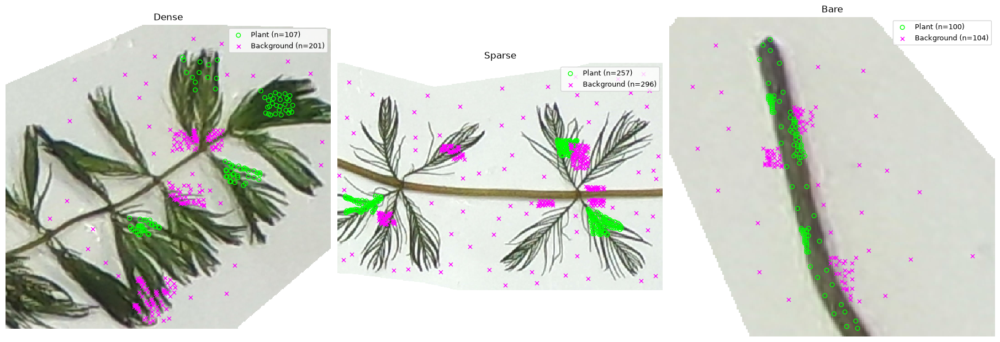

In [27]:
%matplotlib inline

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7),
    constrained_layout=True
)

for ax, name in zip(axes, ["Dense", "Sparse", "Bare"]):
    region = regions[name]

    preview = np.dstack([
        region["rgb"],
        region["roi"].astype(np.uint8) * 255
    ])

    ax.imshow(preview, interpolation="nearest")

    for sample_class, color, marker in [
        ("Plant", "lime", "o"),
        ("Background", "magenta", "x")
    ]:
        points = samples.loc[
            (samples["Region"] == name)
            & (samples["Class"] == sample_class)
        ]

        if marker == "o":
            ax.scatter(
                points["X"], points["Y"],
                s=30,
                facecolors="none",
                edgecolors=color,
                linewidths=1,
                label=f"{sample_class} (n={len(points)})"
            )
        else:
            ax.scatter(
                points["X"], points["Y"],
                s=25,
                color=color,
                marker=marker,
                linewidths=1,
                label=f"{sample_class} (n={len(points)})"
            )

    # Preserve image boundaries after adding the points.
    height, width = region["roi"].shape
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)

    ax.set_title(name)
    ax.axis("off")
    ax.legend(loc="upper right", fontsize=9)

plt.show()

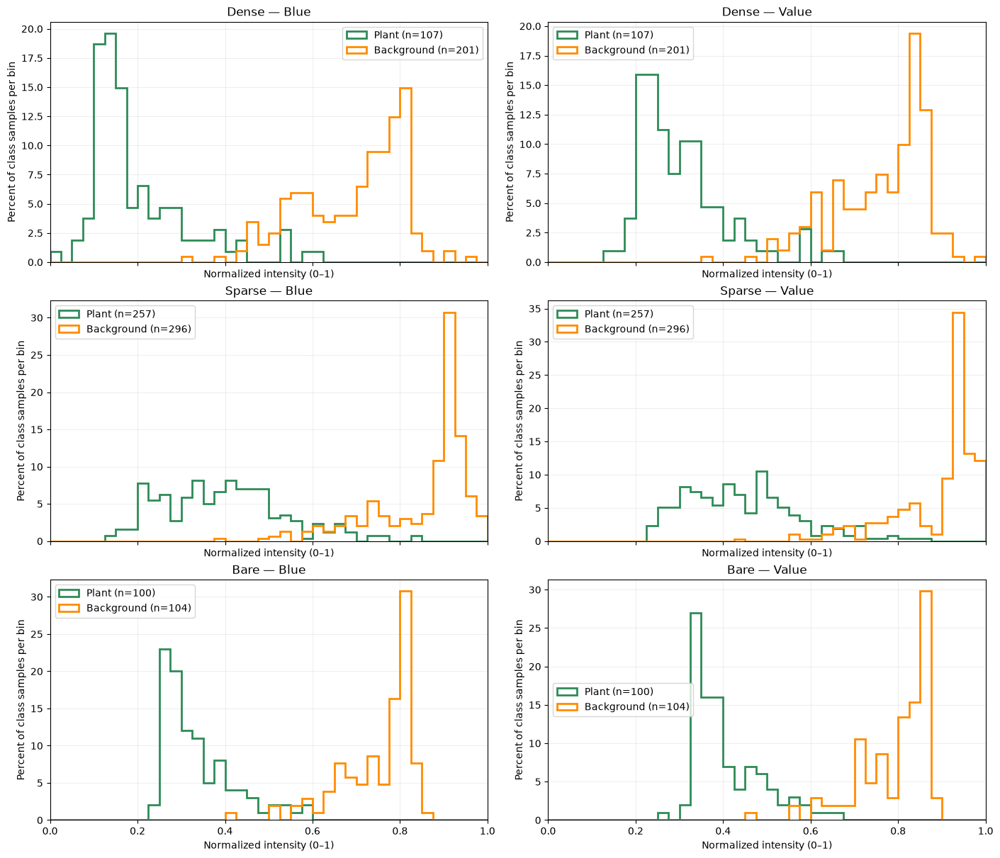

In [29]:
#how much do plant & background values overlap?

%matplotlib inline

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12),
    sharex=True,
    constrained_layout=True
)

bins = np.linspace(0, 1, 41)

for row, name in enumerate(["Dense", "Sparse", "Bare"]):
    region_samples = samples.loc[samples["Region"] == name]

    for col, channel in enumerate(["Blue", "Value"]):
        ax = axes[row, col]

        for sample_class, color in [
            ("Plant", "seagreen"),
            ("Background", "darkorange")
        ]:
            values = region_samples.loc[
                region_samples["Class"] == sample_class,
                channel
            ].dropna()

            if values.empty:
                continue

            ax.hist(
                values,
                bins=bins,
                weights=np.full(len(values), 100.0 / len(values)),
                histtype="step",
                linewidth=2,
                color=color,
                label=f"{sample_class} (n={len(values)})"
            )

        ax.set_title(f"{name} — {channel}")
        ax.set_xlabel("Normalized intensity (0–1)")
        ax.set_ylabel("Percent of class samples per bin")
        ax.set_xlim(0, 1)
        ax.legend()
        ax.grid(alpha=0.2)

plt.show()

In [30]:
# Candidate cutoffs between possible 8-bit intensity levels.
thresholds = np.r_[
    0.0,
    (np.arange(255) + 0.5) / 255.0,
    1.0 + 1e-6
]

threshold_results = []

for name in ["Dense", "Sparse", "Bare"]:
    region_samples = samples.loc[samples["Region"] == name]

    for channel in ["Blue", "Value"]:
        plant = region_samples.loc[
            region_samples["Class"] == "Plant", channel
        ].dropna().to_numpy()

        background = region_samples.loc[
            region_samples["Class"] == "Background", channel
        ].dropna().to_numpy()

        # Rule: intensity below the threshold = plant.
        plant_recall = (
            plant[:, None] < thresholds[None, :]
        ).mean(axis=0)

        background_recall = (
            background[:, None] >= thresholds[None, :]
        ).mean(axis=0)

        balanced_accuracy = (
            plant_recall + background_recall
        ) / 2

        # Select the middle candidate if several tie for best score.
        best_indices = np.flatnonzero(
            np.isclose(
                balanced_accuracy,
                balanced_accuracy.max(),
                rtol=0,
                atol=1e-12
            )
        )
        best = best_indices[len(best_indices) // 2]

        threshold_results.append({
            "Region": name,
            "Channel": channel,
            "Threshold": thresholds[best],
            "Plant missed (%)": 100 * (1 - plant_recall[best]),
            "Background selected (%)": (
                100 * (1 - background_recall[best])
            ),
            "Balanced accuracy (%)": 100 * balanced_accuracy[best]
        })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary.round(3))

,Region,Channel,Threshold,Plant missed (%),Background selected (%),Balanced accuracy (%)
0,Dense,Blue,0.441,5.607,0.995,96.699
1,Dense,Value,0.508,4.673,0.995,97.166
2,Sparse,Blue,0.586,9.339,3.041,93.810
3,Sparse,Value,0.657,7.004,3.041,94.978
4,Bare,Blue,0.567,2.000,3.846,97.077
5,Bare,Value,0.606,3.000,2.885,97.058


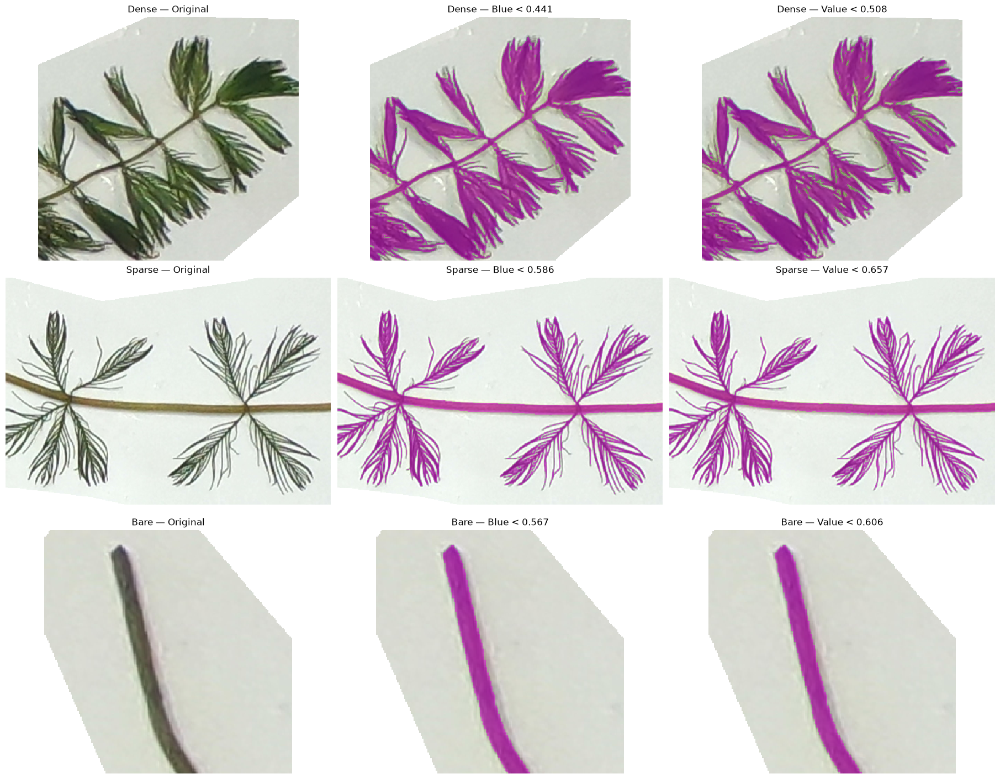

In [31]:
%matplotlib inline

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 14),
    constrained_layout=True
)

region_threshold_masks = {}

for row, name in enumerate(["Dense", "Sparse", "Bare"]):
    region = regions[name]
    rgb_region = region["rgb"]
    valid_region = region["roi"]

    normalized_rgb = rgb_region.astype(float) / 255.0
    hsv_region = rgb_to_hsv(normalized_rgb)

    original = np.dstack([
        rgb_region,
        valid_region.astype(np.uint8) * 255
    ])

    axes[row, 0].imshow(original, interpolation="nearest")
    axes[row, 0].set_title(f"{name} — Original")

    region_threshold_masks[name] = {}

    for col, (channel, values) in enumerate([
        ("Blue", normalized_rgb[:, :, 2]),
        ("Value", hsv_region[:, :, 2])
    ], start=1):
        threshold = threshold_summary.loc[
            (threshold_summary["Region"] == name)
            & (threshold_summary["Channel"] == channel),
            "Threshold"
        ].iloc[0]

        mask = valid_region & (values < threshold)
        region_threshold_masks[name][channel] = mask

        # Transparent overlay: magenta only at selected pixels.
        overlay = np.zeros((*mask.shape, 4), dtype=float)
        overlay[:, :, :3] = [1, 0, 1]
        overlay[:, :, 3] = mask * 0.45

        axes[row, col].imshow(original, interpolation="nearest")
        axes[row, col].imshow(overlay, interpolation="nearest")
        axes[row, col].set_title(
            f"{name} — {channel} < {threshold:.3f}"
        )

    for ax in axes[row]:
        ax.axis("off")

plt.show()

In [5]:
from skimage.filters import threshold_otsu

In [9]:
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()

regions_file = filedialog.askopenfilename(
    title="Select your saved _regions.npz file",
    initialdir=str(project_folder / "DATA" / "cleaned"),
    filetypes=[("Saved regions", "*_regions.npz")]
)

root.destroy()

if not regions_file:
    raise ValueError("No file selected.")

with np.load(regions_file, allow_pickle=False) as saved:
    regions = {
        name: {
            "rgb": saved[f"{name}_rgb"].copy(),
            "roi": saved[f"{name}_roi"].copy(),
            "bounds": tuple(saved[f"{name}_bounds"].tolist())
        }
        for name in ["Dense", "Sparse", "Bare"]
    }

print("Restored regions:", ", ".join(regions))

Restored regions: Dense, Sparse, Bare


In [10]:
otsu_results = []
otsu_masks = {}

for name in ["Dense", "Sparse", "Bare"]:
    region = regions[name]
    valid = region["roi"]

    rgb_region = region["rgb"].astype(float) / 255.0
    hsv_region = rgb_to_hsv(rgb_region)

    otsu_masks[name] = {}

    for channel, values in [
        ("Blue", rgb_region[:, :, 2]),
        ("Value", hsv_region[:, :, 2])
    ]:
        # Compute the cutoff using only pixels inside this region.
        threshold = threshold_otsu(values[valid])

        # Apply that region's cutoff.
        mask = valid & (values < threshold)
        otsu_masks[name][channel] = mask

        otsu_results.append({
            "Region": name,
            "Channel": channel,
            "Otsu threshold": threshold
        })

otsu_summary = pd.DataFrame(otsu_results)
display(otsu_summary.round(3))

,Region,Channel,Otsu threshold
0,Dense,Blue,0.511
1,Dense,Value,0.578
2,Sparse,Blue,0.655
3,Sparse,Value,0.705
4,Bare,Blue,0.564
5,Bare,Value,0.620


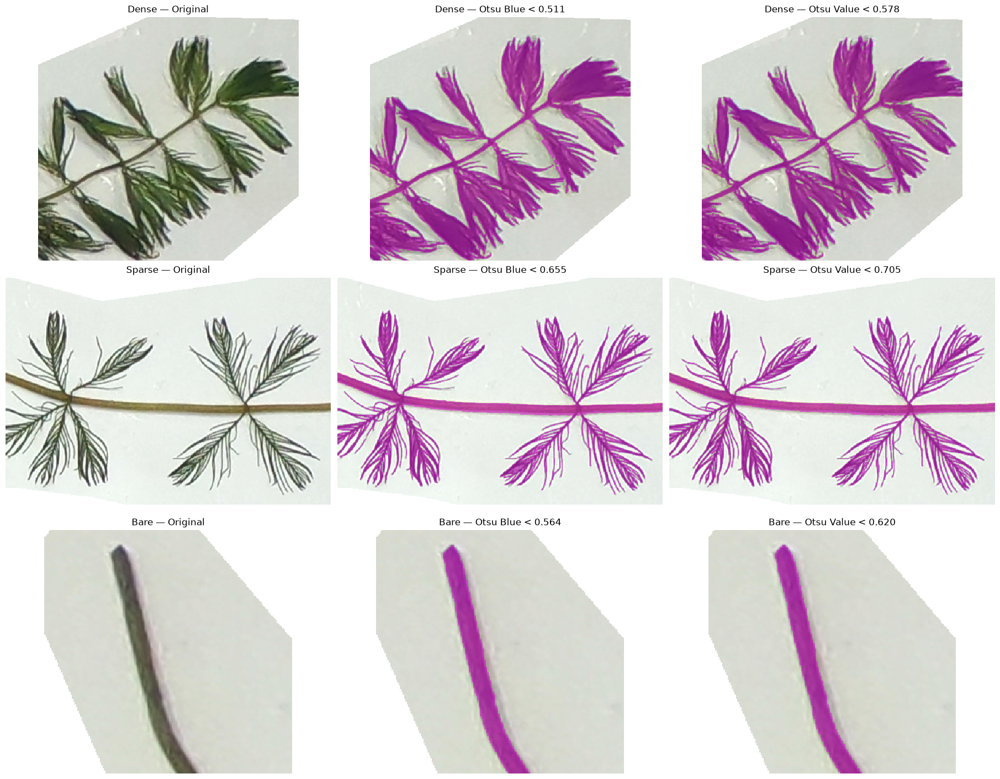

In [11]:
%matplotlib inline

fig, axes = plt.subplots(
    3, 3, figsize=(18, 14),
    constrained_layout=True
)

for row, name in enumerate(["Dense", "Sparse", "Bare"]):
    region = regions[name]

    original = np.dstack([
        region["rgb"],
        region["roi"].astype(np.uint8) * 255
    ])

    axes[row, 0].imshow(original, interpolation="nearest")
    axes[row, 0].set_title(f"{name} — Original")

    for col, channel in enumerate(["Blue", "Value"], start=1):
        mask = otsu_masks[name][channel]

        threshold = otsu_summary.loc[
            (otsu_summary["Region"] == name)
            & (otsu_summary["Channel"] == channel),
            "Otsu threshold"
        ].iloc[0]

        overlay = np.zeros((*mask.shape, 4), dtype=float)
        overlay[:, :, :3] = [1, 0, 1]
        overlay[:, :, 3] = mask * 0.45

        axes[row, col].imshow(original, interpolation="nearest")
        axes[row, col].imshow(overlay, interpolation="nearest")
        axes[row, col].set_title(
            f"{name} — Otsu {channel} < {threshold:.3f}"
        )

    for ax in axes[row]:
        ax.axis("off")

plt.show()

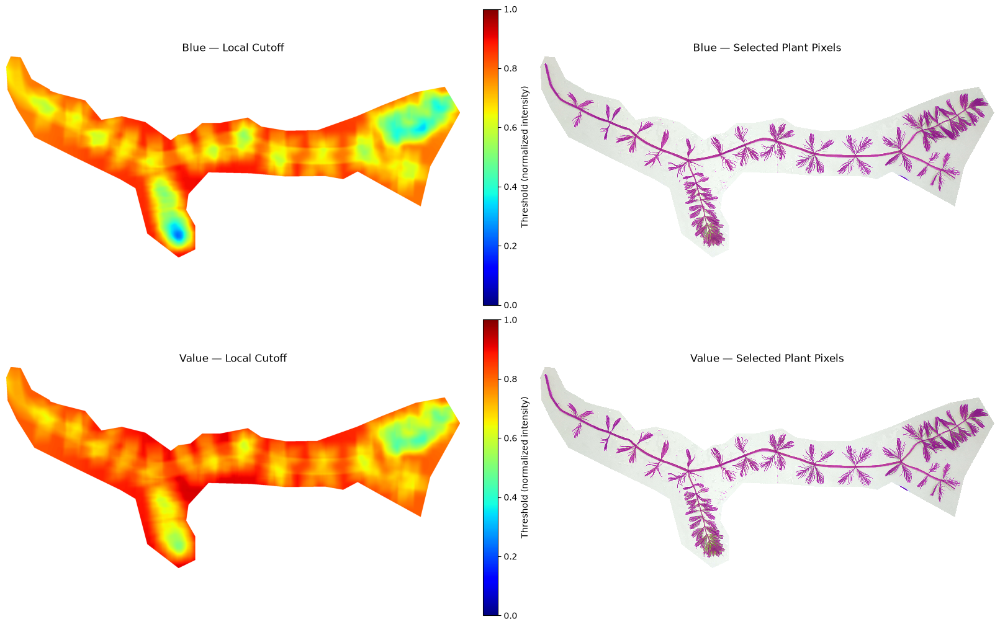

In [19]:
from scipy.ndimage import uniform_filter

# Starting parameters to explore.
window_size = 101  # 101 × 101 original image pixels
offset = 0.05      # Difference in normalized intensity

rgb_normalized = branch_crop.astype(float) / 255.0
hsv_crop = rgb_to_hsv(rgb_normalized)

# Exclude pixels outside the polygon from neighborhood calculations.
weights = uniform_filter(
    roi_mask.astype(float),
    size=window_size,
    mode="constant",
    cval=0
)

adaptive_masks = {}
threshold_maps = {}

fig, axes = plt.subplots(
    2, 2, figsize=(16, 10),
    constrained_layout=True
)

original = np.dstack([
    branch_crop,
    roi_mask.astype(np.uint8) * 255
])

for row, (channel, intensity) in enumerate([
    ("Blue", rgb_normalized[:, :, 2]),
    ("Value", hsv_crop[:, :, 2])
]):
    weighted_mean = uniform_filter(
        intensity * roi_mask,
        size=window_size,
        mode="constant",
        cval=0
    )

    neighborhood_mean = np.divide(
        weighted_mean,
        weights,
        out=np.zeros_like(intensity),
        where=weights > 0
    )

    threshold_map = neighborhood_mean - offset
    plant_mask = roi_mask & (intensity < threshold_map)

    threshold_maps[channel] = threshold_map
    adaptive_masks[channel] = plant_mask

    # Show how the cutoff varies across the crop.
    im = axes[row, 0].imshow(
        np.ma.array(threshold_map, mask=~roi_mask),
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 0].set_title(f"{channel} — Local Cutoff")
    fig.colorbar(
        im, ax=axes[row, 0],
        label="Threshold (normalized intensity)"
    )

    # Show selected plant pixels over the original photograph.
    overlay = np.zeros((*plant_mask.shape, 4))
    overlay[:, :, :3] = [1, 0, 1]
    overlay[:, :, 3] = plant_mask * 0.45

    axes[row, 1].imshow(original, interpolation="nearest")
    axes[row, 1].imshow(overlay, interpolation="nearest")
    axes[row, 1].set_title(f"{channel} — Selected Plant Pixels")

    for ax in axes[row]:
        ax.axis("off")

plt.show()

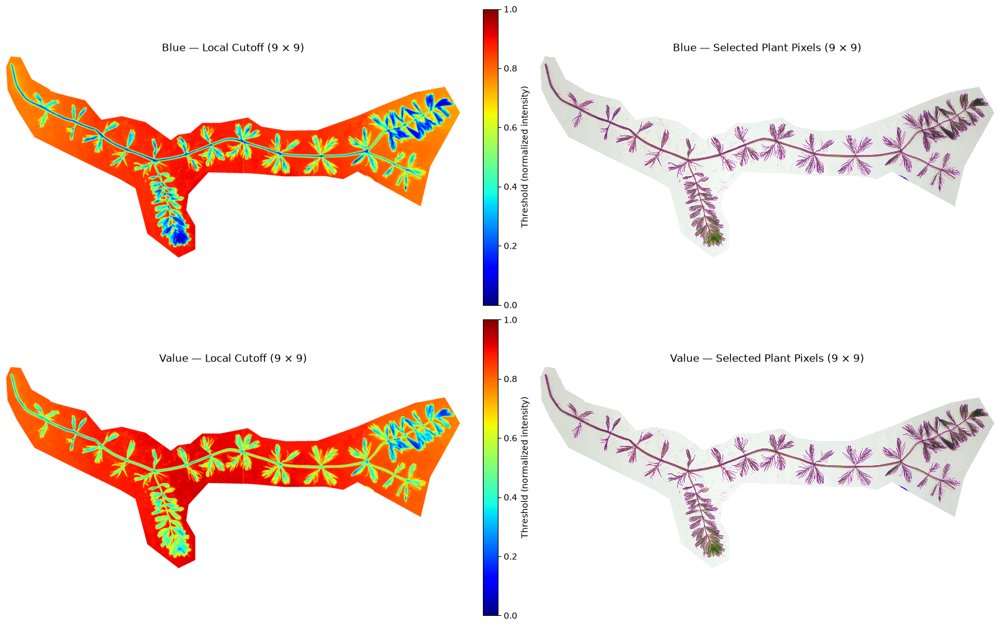

In [22]:
%matplotlib inline

from scipy.ndimage import uniform_filter

# Adaptive threshold settings.
window_size = 9  # 9 × 9 original image pixels
offset = 0.05

rgb_normalized = branch_crop.astype(float) / 255.0
hsv_crop = rgb_to_hsv(rgb_normalized)

# Exclude pixels outside the polygon from neighborhood calculations.
weights = uniform_filter(
    roi_mask.astype(float),
    size=window_size,
    mode="constant",
    cval=0
)

adaptive_masks = {}
threshold_maps = {}

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    constrained_layout=True
)

original = np.dstack([
    branch_crop,
    roi_mask.astype(np.uint8) * 255
])

for row, (channel, intensity) in enumerate([
    ("Blue", rgb_normalized[:, :, 2]),
    ("Value", hsv_crop[:, :, 2])
]):
    # Calculate the neighborhood mean using only valid pixels.
    weighted_mean = uniform_filter(
        intensity * roi_mask,
        size=window_size,
        mode="constant",
        cval=0
    )

    neighborhood_mean = np.divide(
        weighted_mean,
        weights,
        out=np.zeros_like(intensity),
        where=weights > 0
    )

    # A pixel is selected if darker than its local mean minus offset.
    threshold_map = neighborhood_mean - offset
    plant_mask = roi_mask & (intensity < threshold_map)

    threshold_maps[channel] = threshold_map
    adaptive_masks[channel] = plant_mask

    # Display the spatially varying thresholds.
    im = axes[row, 0].imshow(
        np.ma.array(threshold_map, mask=~roi_mask),
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 0].set_title(
        f"{channel} — Local Cutoff (9 × 9)"
    )

    fig.colorbar(
        im,
        ax=axes[row, 0],
        label="Threshold (normalized intensity)"
    )

    # Overlay selected pixels on the original photograph.
    overlay = np.zeros((*plant_mask.shape, 4), dtype=float)
    overlay[:, :, :3] = [1, 0, 1]
    overlay[:, :, 3] = plant_mask * 0.45

    axes[row, 1].imshow(original, interpolation="nearest")
    axes[row, 1].imshow(overlay, interpolation="nearest")
    axes[row, 1].set_title(
        f"{channel} — Selected Plant Pixels (9 × 9)"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.show()

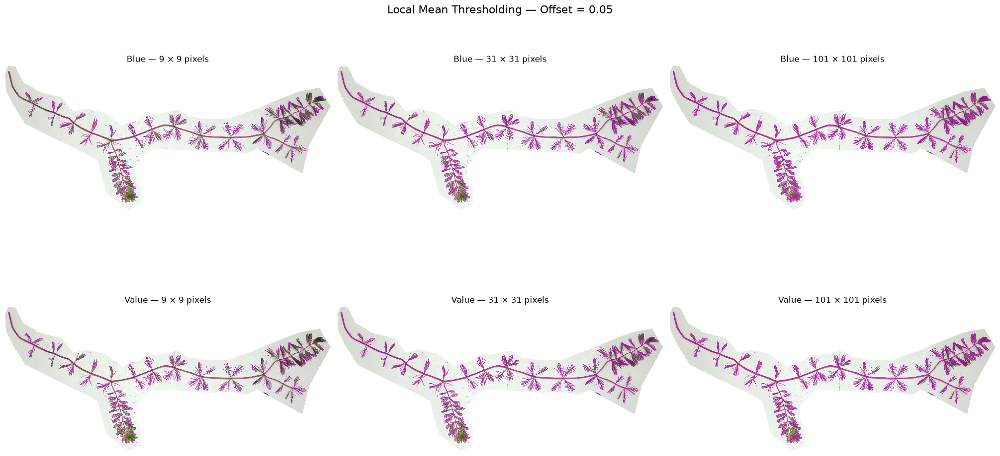

In [23]:
%matplotlib inline

from scipy.ndimage import uniform_filter

window_sizes = [9, 31, 101]
comparison_offset = 0.05

rgb_normalized = branch_crop.astype(float) / 255.0
hsv_comparison = rgb_to_hsv(rgb_normalized)

original = np.dstack([
    branch_crop,
    roi_mask.astype(np.uint8) * 255
])

# Store results without replacing previous masks.
window_comparison_masks = {}

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 10),
    constrained_layout=True
)

for col, window in enumerate(window_sizes):
    weights = uniform_filter(
        roi_mask.astype(float),
        size=window,
        mode="constant",
        cval=0
    )

    window_comparison_masks[window] = {}

    for row, (channel, intensity) in enumerate([
        ("Blue", rgb_normalized[:, :, 2]),
        ("Value", hsv_comparison[:, :, 2])
    ]):
        weighted_mean = uniform_filter(
            intensity * roi_mask,
            size=window,
            mode="constant",
            cval=0
        )

        neighborhood_mean = np.divide(
            weighted_mean,
            weights,
            out=np.zeros_like(intensity),
            where=weights > 0
        )

        threshold_map = neighborhood_mean - comparison_offset
        plant_mask = roi_mask & (intensity < threshold_map)

        window_comparison_masks[window][channel] = plant_mask

        overlay = np.zeros((*plant_mask.shape, 4), dtype=float)
        overlay[:, :, :3] = [1, 0, 1]
        overlay[:, :, 3] = plant_mask * 0.45

        ax = axes[row, col]
        ax.imshow(original, interpolation="nearest")
        ax.imshow(overlay, interpolation="nearest")
        ax.set_title(f"{channel} — {window} × {window} pixels")
        ax.axis("off")

fig.suptitle(
    "Local Mean Thresholding — Offset = 0.05",
    fontsize=16
)

plt.show()

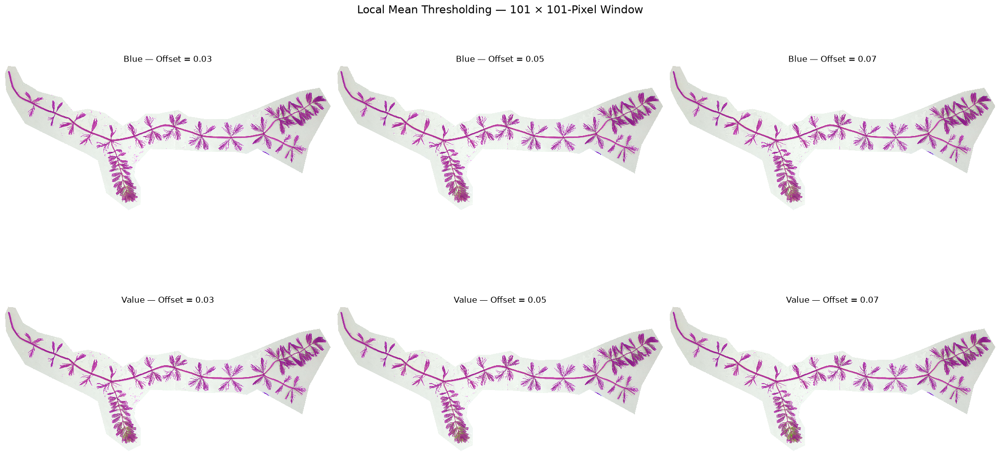

In [24]:
%matplotlib inline

from scipy.ndimage import uniform_filter

comparison_window = 101
offsets = [0.03, 0.05, 0.07]

rgb_normalized = branch_crop.astype(float) / 255.0
hsv_comparison = rgb_to_hsv(rgb_normalized)

original = np.dstack([
    branch_crop,
    roi_mask.astype(np.uint8) * 255
])

weights = uniform_filter(
    roi_mask.astype(float),
    size=comparison_window,
    mode="constant",
    cval=0
)

# Keep these results separate from previous comparisons.
offset_comparison_masks = {}

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 10),
    constrained_layout=True
)

for row, (channel, intensity) in enumerate([
    ("Blue", rgb_normalized[:, :, 2]),
    ("Value", hsv_comparison[:, :, 2])
]):
    # The neighborhood mean stays the same across offsets.
    weighted_mean = uniform_filter(
        intensity * roi_mask,
        size=comparison_window,
        mode="constant",
        cval=0
    )

    neighborhood_mean = np.divide(
        weighted_mean,
        weights,
        out=np.zeros_like(intensity),
        where=weights > 0
    )

    offset_comparison_masks[channel] = {}

    for col, offset in enumerate(offsets):
        threshold_map = neighborhood_mean - offset
        plant_mask = roi_mask & (intensity < threshold_map)

        offset_comparison_masks[channel][offset] = plant_mask

        overlay = np.zeros((*plant_mask.shape, 4), dtype=float)
        overlay[:, :, :3] = [1, 0, 1]
        overlay[:, :, 3] = plant_mask * 0.45

        ax = axes[row, col]
        ax.imshow(original, interpolation="nearest")
        ax.imshow(overlay, interpolation="nearest")
        ax.set_title(f"{channel} — Offset = {offset:.2f}")
        ax.axis("off")

fig.suptitle(
    "Local Mean Thresholding — 101 × 101-Pixel Window",
    fontsize=16
)

plt.show()

In [25]:
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(original, interpolation="nearest")
ax.set_title("Click two opposite corners around missed tissue")

zoom_points = plt.ginput(2, timeout=0)
plt.close(fig)

if len(zoom_points) != 2:
    raise ValueError("Select two corners.")

corners = np.array(zoom_points)
height, width = roi_mask.shape

zx0, zy0 = np.floor(corners.min(axis=0)).astype(int)
zx1, zy1 = np.ceil(corners.max(axis=0)).astype(int)

zx0, zx1 = np.clip([zx0, zx1], 0, width)
zy0, zy1 = np.clip([zy0, zy1], 0, height)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle with a nonzero area.")

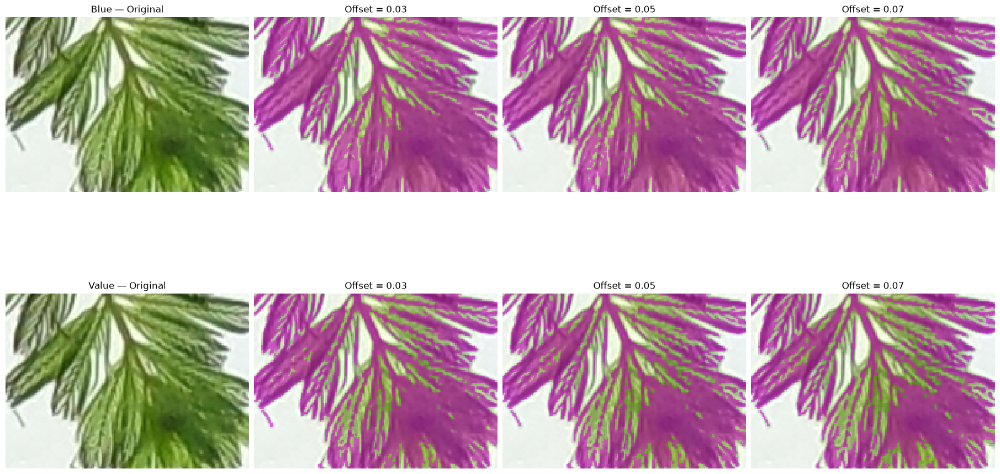

In [26]:
%matplotlib inline

fig, axes = plt.subplots(
    2, 4, figsize=(18, 10),
    constrained_layout=True
)

patch = original[zy0:zy1, zx0:zx1]

for row, channel in enumerate(["Blue", "Value"]):
    axes[row, 0].imshow(patch, interpolation="nearest")
    axes[row, 0].set_title(f"{channel} — Original")

    for col, offset in enumerate([0.03, 0.05, 0.07], start=1):
        mask = offset_comparison_masks[channel][offset][
            zy0:zy1, zx0:zx1
        ]

        overlay = np.zeros((*mask.shape, 4), dtype=float)
        overlay[:, :, :3] = [1, 0, 1]
        overlay[:, :, 3] = mask * 0.45

        axes[row, col].imshow(patch, interpolation="nearest")
        axes[row, col].imshow(overlay, interpolation="nearest")
        axes[row, col].set_title(f"Offset = {offset:.2f}")

    for ax in axes[row]:
        ax.axis("off")

plt.show()

In [27]:
%matplotlib tk

# Use the existing zoom rectangle.
error_rgb = branch_crop[zy0:zy1, zx0:zx1]
error_roi = roi_mask[zy0:zy1, zx0:zx1]

error_mask = offset_comparison_masks["Blue"][0.05][
    zy0:zy1, zx0:zx1
]

error_hsv = rgb_to_hsv(error_rgb.astype(float) / 255.0)
height, width = error_roi.shape

preview = np.dstack([
    error_rgb,
    error_roi.astype(np.uint8) * 255
])

overlay = np.zeros((*error_mask.shape, 4), dtype=float)
overlay[:, :, :3] = [1, 0, 1]
overlay[:, :, 3] = error_mask * 0.35

error_records = []
used_pixels = set()

for label, instruction in [
    ("Missed plant", "Click plant tissue WITHOUT magenta"),
    ("False plant", "Click BACKGROUND GAPS covered in magenta")
]:
    fig, ax = plt.subplots(figsize=(13, 9))
    ax.imshow(preview, interpolation="nearest")
    ax.imshow(overlay, interpolation="nearest")
    ax.set_title(
        f"{instruction}\n"
        "Right-click: undo | Enter: finish | Turn toolbar zoom off before clicking"
    )

    points = plt.ginput(n=-1, timeout=0)
    plt.close(fig)

    accepted = 0
    skipped = 0

    for x, y in points:
        xi, yi = int(np.rint(x)), int(np.rint(y))

        if not (0 <= xi < width and 0 <= yi < height):
            skipped += 1
            continue

        if not error_roi[yi, xi] or (xi, yi) in used_pixels:
            skipped += 1
            continue

        # Confirm the pixel actually has the specified model error.
        predicted_plant = bool(error_mask[yi, xi])

        if (
            (label == "Missed plant" and predicted_plant)
            or (label == "False plant" and not predicted_plant)
        ):
            skipped += 1
            continue

        used_pixels.add((xi, yi))

        r, g, b = error_rgb[yi, xi].astype(float) / 255.0
        h, s, v = error_hsv[yi, xi]

        error_records.append({
            "Error": label,
            "Class": "Plant" if label == "Missed plant" else "Background",
            "X_crop": xi + zx0,
            "Y_crop": yi + zy0,
            "Red": r,
            "Green": g,
            "Blue": b,
            "Hue": h,
            "Saturation": s,
            "Value": v
        })
        accepted += 1

    print(f"{label}: {accepted} accepted; {skipped} skipped")

error_samples = pd.DataFrame(error_records)

# Save immediately, including the exact crop used for coordinates.
if not error_samples.empty:
    save_folder = project_folder / "DATA" / "cleaned"
    save_folder.mkdir(parents=True, exist_ok=True)

    stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S_%f")
    save_base = save_folder / f"segmentation_error_samples_{stamp}"

    error_samples.to_csv(
        save_base.with_suffix(".csv"),
        index=False
    )

    np.savez_compressed(
        save_base.with_suffix(".npz"),
        branch_crop=branch_crop,
        roi_mask=roi_mask,
        zoom_bounds=np.array([zx0, zy0, zx1, zy1]),
        blue_mask=offset_comparison_masks["Blue"][0.05],
        window_size=101,
        offset=0.05
    )

    print(f"Saved to: {save_folder}")
    display(error_samples.groupby("Error").size().rename("Samples"))
else:
    print("No valid error samples selected.")

Missed plant: 58 accepted; 8 skipped
False plant: 78 accepted; 9 skipped
Saved to: C:\Users\mguar\Documents\OEAS805\FinalProject\DATA\cleaned


Error
False plant     78
Missed plant    58
Name: Samples, dtype: int64

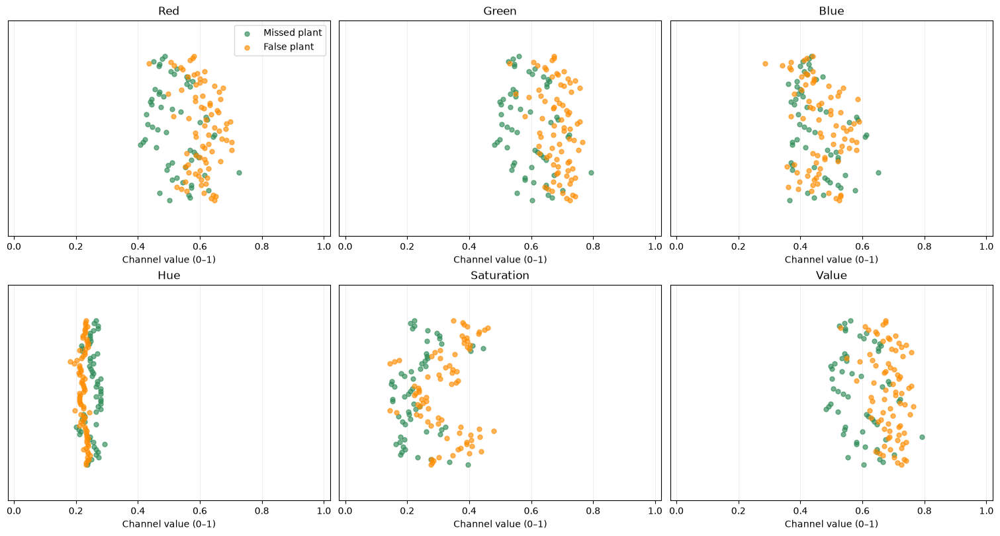

In [28]:
%matplotlib inline

channels = ["Red", "Green", "Blue", "Hue", "Saturation", "Value"]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8),
    constrained_layout=True
)

for ax, channel in zip(axes.flat, channels):
    for label, color in [
        ("Missed plant", "seagreen"),
        ("False plant", "darkorange")
    ]:
        values = error_samples.loc[
            error_samples["Error"] == label, channel
        ]

        if values.empty:
            continue

        # Plot each sampled pixel; vertical spread is just for visibility.
        ax.scatter(
            values,
            np.linspace(-0.08, 0.08, len(values)),
            color=color,
            alpha=0.65,
            s=25,
            label=label
        )

    ax.set_title(channel)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.12, 0.12)
    ax.set_yticks([])
    ax.set_xlabel("Channel value (0–1)")
    ax.grid(axis="x", alpha=0.2)

axes[0, 0].legend()
plt.show()

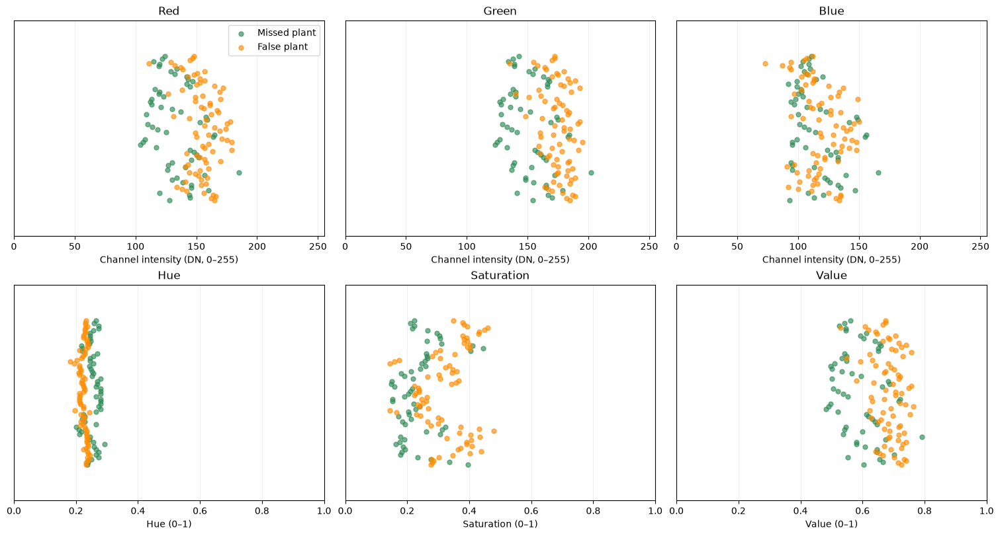

In [29]:
%matplotlib inline

channels = ["Red", "Green", "Blue", "Hue", "Saturation", "Value"]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8),
    constrained_layout=True
)

for ax, channel in zip(axes.flat, channels):
    is_rgb = channel in ["Red", "Green", "Blue"]

    for label, color in [
        ("Missed plant", "seagreen"),
        ("False plant", "darkorange")
    ]:
        values = error_samples.loc[
            error_samples["Error"] == label, channel
        ].to_numpy()

        if values.size == 0:
            continue

        if is_rgb:
            values = np.rint(values * 255)

        ax.scatter(
            values,
            np.linspace(-0.08, 0.08, len(values)),
            color=color,
            alpha=0.65,
            s=25,
            label=label
        )

    ax.set_title(channel)
    ax.set_ylim(-0.12, 0.12)
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.2)

    if is_rgb:
        ax.set_xlim(0, 255)
        ax.set_xlabel("Channel intensity (DN, 0–255)")
    else:
        ax.set_xlim(0, 1)
        ax.set_xlabel(f"{channel} (0–1)")

axes[0, 0].legend()
plt.show()

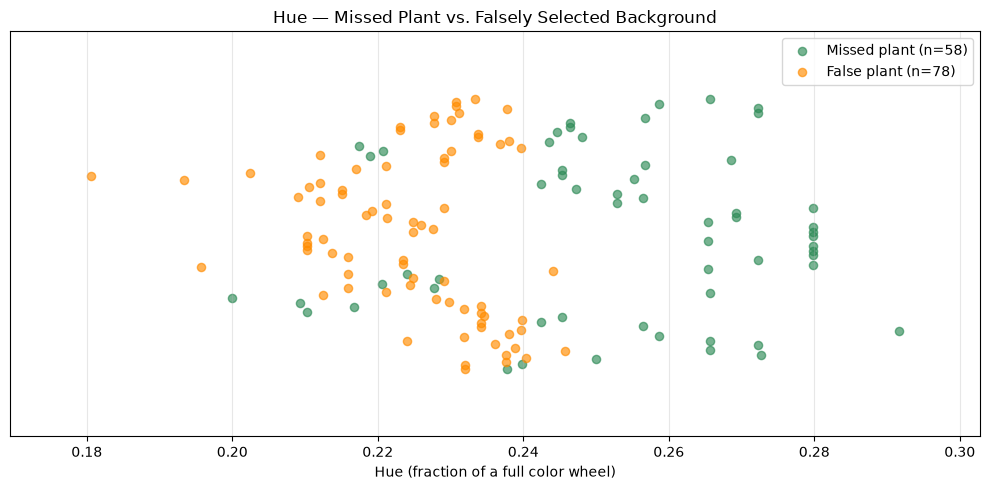

In [30]:
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 5))

for label, color in [
    ("Missed plant", "seagreen"),
    ("False plant", "darkorange")
]:
    values = error_samples.loc[
        error_samples["Error"] == label, "Hue"
    ].dropna().to_numpy()

    ax.scatter(
        values,
        np.linspace(-0.08, 0.08, len(values)),
        color=color,
        alpha=0.65,
        s=35,
        label=f"{label} (n={len(values)})"
    )

# Zoom to the sampled hue range, with a little padding.
hues = error_samples["Hue"].dropna()
padding = max(0.005, (hues.max() - hues.min()) * 0.1)

ax.set_xlim(
    max(0, hues.min() - padding),
    min(1, hues.max() + padding)
)
ax.set_ylim(-0.12, 0.12)
ax.set_yticks([])
ax.set_xlabel("Hue (fraction of a full color wheel)")
ax.set_title("Hue — Missed Plant vs. Falsely Selected Background")
ax.grid(axis="x", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [31]:
hue_cutoff = 0.24

for label in ["Missed plant", "False plant"]:
    hues = error_samples.loc[
        error_samples["Error"] == label, "Hue"
    ].dropna()

    selected = hues > hue_cutoff

    print(
        f"{label}: {selected.sum()} of {len(hues)} "
        f"({selected.mean():.1%}) classified as plant"
    )

Missed plant: 45 of 58 (77.6%) classified as plant
False plant: 3 of 78 (3.8%) classified as plant


In [34]:
sample_files = sorted(
    (project_folder / "DATA" / "cleaned").glob(
        "*_labeled_samples_*.csv"
    )
)

for i, path in enumerate(sample_files):
    print(f"{i}: {path.name}")

if not sample_files:
    print("No labeled-sample CSV files found.")

0: GOPR1100_labeled_samples_20261103_222001_311278.csv


In [35]:
# Replace 0 if your saved samples have a different number above.
samples = pd.read_csv(sample_files[0])

display(
    samples.groupby(["Region", "Class"])
    .size()
    .rename("Samples")
)

Region  Class     
Bare    Background    104
        Plant         100
Dense   Background    201
        Plant         107
Sparse  Background    296
        Plant         257
Name: Samples, dtype: int64

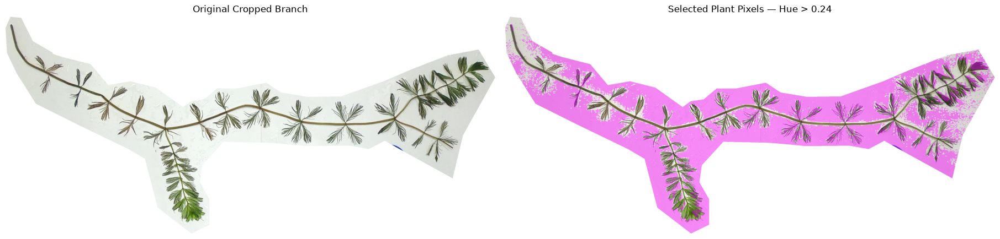

,Region,Plant samples,Background samples,Plant missed (%),Background selected (%),Balanced accuracy (%)
0,Dense,107,201,28.97,26.87,72.08
1,Sparse,257,296,25.68,72.30,51.01
2,Bare,100,104,83.00,4.81,56.10


In [36]:
%matplotlib inline

hue_cutoff = 0.24

# Calculate hue across the whole cropped branch.
hsv_crop = rgb_to_hsv(branch_crop.astype(float) / 255.0)

hue_plant_mask = roi_mask.astype(bool) & (
    hsv_crop[:, :, 0] > hue_cutoff
)

# Show the original image and selected pixels.
original_rgba = np.dstack([
    branch_crop,
    roi_mask.astype(np.uint8) * 255
])

overlay = np.zeros((*roi_mask.shape, 4), dtype=float)
overlay[hue_plant_mask] = [1, 0, 1, 0.45]

fig, axes = plt.subplots(
    1, 2, figsize=(18, 8),
    constrained_layout=True
)

axes[0].imshow(original_rgba)
axes[0].set_title("Original Cropped Branch")

axes[1].imshow(original_rgba)
axes[1].imshow(overlay)
axes[1].set_title(f"Selected Plant Pixels — Hue > {hue_cutoff}")

for ax in axes:
    ax.axis("off")

plt.show()

# Evaluate the same rule using the ORIGINAL labeled samples.
# Use their saved hue values directly, so no coordinate mapping is needed.
hue_results = []

for name in ["Dense", "Sparse", "Bare"]:
    region_samples = samples.loc[samples["Region"] == name]

    plant_hues = region_samples.loc[
        region_samples["Class"] == "Plant", "Hue"
    ].dropna()

    background_hues = region_samples.loc[
        region_samples["Class"] == "Background", "Hue"
    ].dropna()

    plant_recall = (plant_hues > hue_cutoff).mean()
    background_recall = (background_hues <= hue_cutoff).mean()

    hue_results.append({
        "Region": name,
        "Plant samples": len(plant_hues),
        "Background samples": len(background_hues),
        "Plant missed (%)": 100 * (1 - plant_recall),
        "Background selected (%)": 100 * (1 - background_recall),
        "Balanced accuracy (%)": (
            100 * (plant_recall + background_recall) / 2
        )
    })

hue_summary = pd.DataFrame(hue_results)
display(hue_summary.round(2))

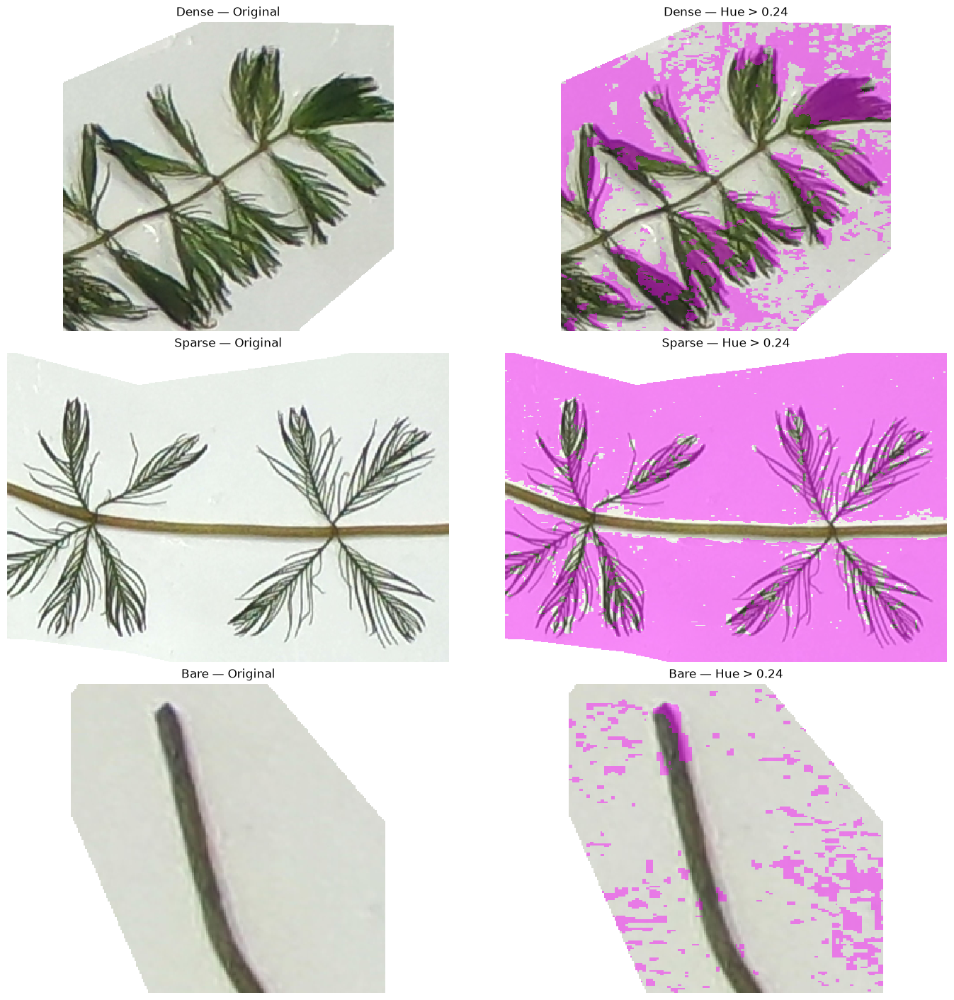

In [37]:
%matplotlib inline

hue_cutoff = 0.24

fig, axes = plt.subplots(
    3, 2, figsize=(14, 14),
    constrained_layout=True
)

for row, name in enumerate(["Dense", "Sparse", "Bare"]):
    rgb = regions[name]["rgb"]
    valid = regions[name]["roi"].astype(bool)

    hsv = rgb_to_hsv(rgb.astype(float) / 255.0)
    selected = valid & (hsv[:, :, 0] > hue_cutoff)

    # Transparent outside the region polygon.
    original = np.dstack([
        rgb,
        valid.astype(np.uint8) * 255
    ])

    overlay = np.zeros((*valid.shape, 4), dtype=float)
    overlay[selected] = [1, 0, 1, 0.45]

    axes[row, 0].imshow(original, interpolation="nearest")
    axes[row, 0].set_title(f"{name} — Original")

    axes[row, 1].imshow(original, interpolation="nearest")
    axes[row, 1].imshow(overlay, interpolation="nearest")
    axes[row, 1].set_title(f"{name} — Hue > {hue_cutoff}")

    for ax in axes[row]:
        ax.axis("off")

plt.show()